# Wine Quality Prediction — Machine Learning Project

**Goal:** Predict whether a wine is of **GOOD** quality (rating ≥ 7) or **BAD** quality (rating < 7) using its physicochemical properties.

**Steps covered:**
1. Load data & explore (`head`, `info`, `describe`)
2. Check missing values & correlations
3. Create binary target `quality_label`
4. Train/test split
5. Logistic Regression (no scaling)
6. Logistic Regression (with `StandardScaler`) — compare
7. Compare Logistic Regression vs KNN vs Decision Tree
8. Hyperparameter tuning (`GridSearchCV`) on the best model
9. Feature importance analysis


## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay,
                              classification_report)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)


## 2. Load the Dataset

In Google Colab, first upload the CSV (or mount Google Drive), then read it with pandas.

```python
# In Colab:
# from google.colab import files
# uploaded = files.upload()   # choose winequality.csv
```


In [2]:
df = pd.read_csv("winequality.csv")
df.head()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### 2.1 Basic Info

In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


### 2.2 Statistical Summary

In [4]:
df.describe()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


## 3. Check for Missing Values

In [5]:
missing = df.isnull().sum()
print(missing)
print("\nTotal missing values:", missing.sum())


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total missing values: 0


## 4. Correlation Analysis

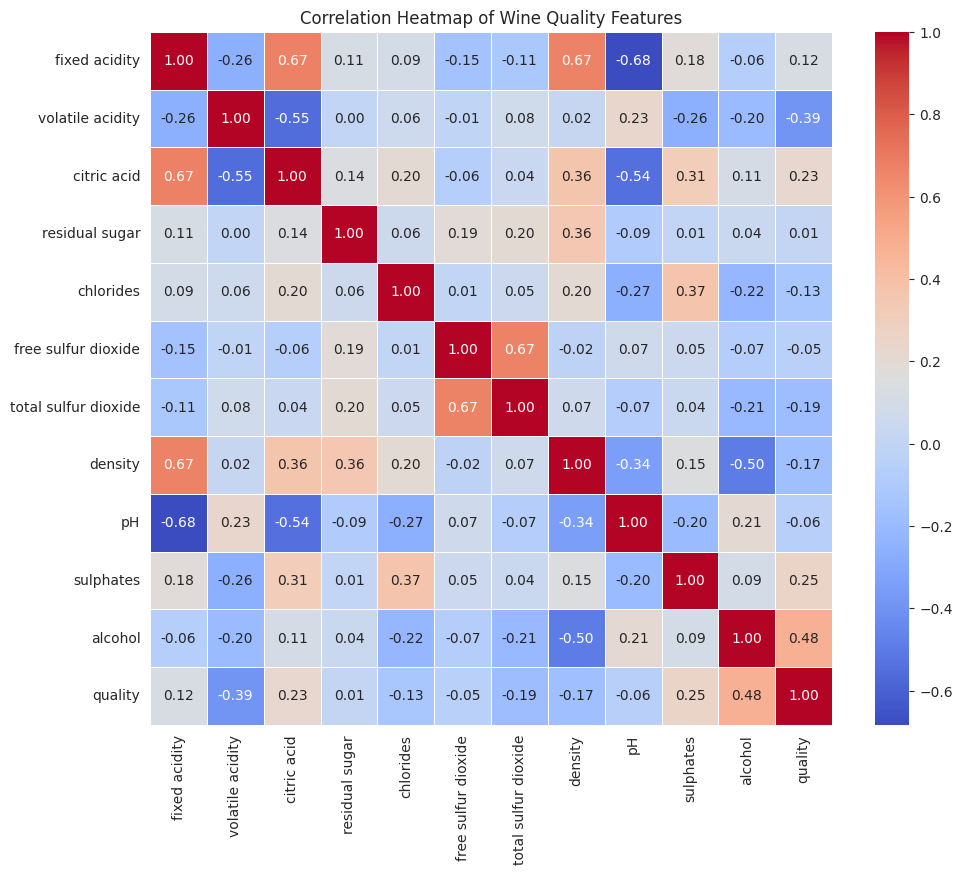

In [6]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap of Wine Quality Features")
plt.show()


In [7]:
quality_corr = corr["quality"].sort_values(ascending=False)
print("Correlation of each feature with 'quality':\n")
print(quality_corr)


Correlation of each feature with 'quality':

quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


**Observation:** `alcohol` tends to have the strongest positive correlation with quality, while `volatile acidity` tends to have the strongest negative correlation. Other features show weaker relationships.

## 5. Create the Binary Target: `quality_label`

- `quality >= 7`  →  **1 (GOOD)**
- `quality < 7`   →  **0 (BAD)**


quality_label
0    1382
1     217
Name: count, dtype: int64

Class proportions:
quality_label
0    0.86429
1    0.13571
Name: proportion, dtype: float64


/tmp/ipykernel_573/517702384.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="quality_label", data=df, palette="viridis")


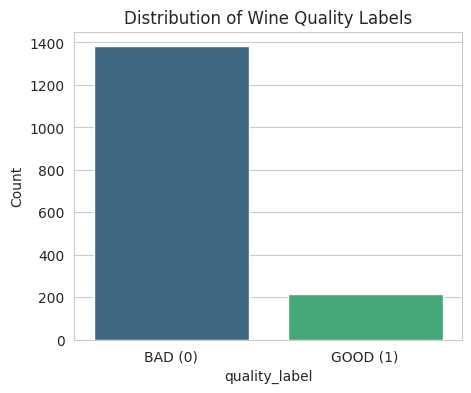

In [8]:
df["quality_label"] = (df["quality"] >= 7).astype(int)

print(df["quality_label"].value_counts())
print("\nClass proportions:")
print(df["quality_label"].value_counts(normalize=True))

plt.figure(figsize=(5, 4))
sns.countplot(x="quality_label", data=df, palette="viridis")
plt.xticks([0, 1], ["BAD (0)", "GOOD (1)"])
plt.title("Distribution of Wine Quality Labels")
plt.ylabel("Count")
plt.show()


**Note:** The dataset is imbalanced — far fewer GOOD wines than BAD wines. This is important context when interpreting accuracy vs. precision/recall.

## 6. Separate Features & Target, Train-Test Split

In [9]:
X = df.drop(columns=["quality", "quality_label"])
y = df["quality_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (1279, 11)  Test shape: (320, 11)


## 7. Logistic Regression — WITHOUT Scaling

--- Logistic Regression (No Scaling) ---
Accuracy : 0.8938
Precision: 0.7368
Recall   : 0.3256
F1-score : 0.4516


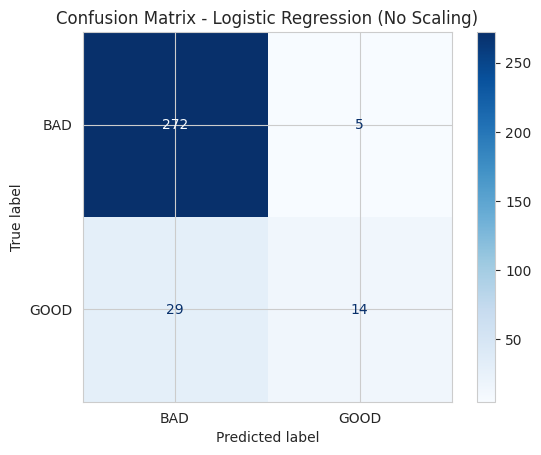

In [10]:
log_reg_raw = LogisticRegression(max_iter=5000, random_state=42)
log_reg_raw.fit(X_train, y_train)

y_pred_raw = log_reg_raw.predict(X_test)

def evaluate_model(y_true, y_pred, model_name="Model"):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    print(f"--- {model_name} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")
    return {"model": model_name, "accuracy": acc, "precision": prec,
            "recall": rec, "f1": f1}

results_raw = evaluate_model(y_test, y_pred_raw, "Logistic Regression (No Scaling)")

cm_raw = confusion_matrix(y_test, y_pred_raw)
ConfusionMatrixDisplay(cm_raw, display_labels=["BAD", "GOOD"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression (No Scaling)")
plt.show()


## 8. Apply StandardScaler & Retrain Logistic Regression

--- Logistic Regression (Scaled) ---
Accuracy : 0.8938
Precision: 0.6957
Recall   : 0.3721
F1-score : 0.4848


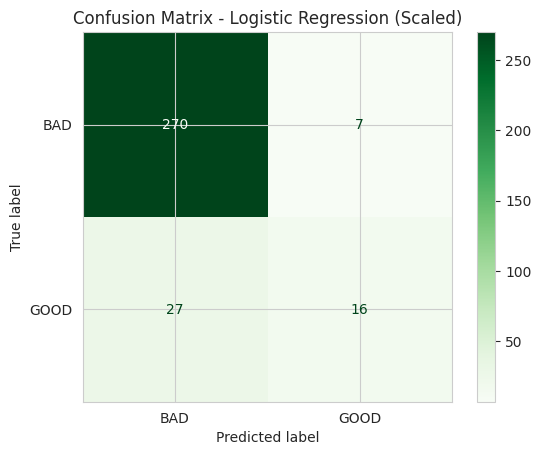

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg_scaled = LogisticRegression(max_iter=5000, random_state=42)
log_reg_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = log_reg_scaled.predict(X_test_scaled)

results_scaled = evaluate_model(y_test, y_pred_scaled, "Logistic Regression (Scaled)")

cm_scaled = confusion_matrix(y_test, y_pred_scaled)
ConfusionMatrixDisplay(cm_scaled, display_labels=["BAD", "GOOD"]).plot(cmap="Greens")
plt.title("Confusion Matrix - Logistic Regression (Scaled)")
plt.show()


### 8.1 Before vs. After Scaling

In [12]:
comparison_df = pd.DataFrame([results_raw, results_scaled]).set_index("model")
comparison_df


,accuracy,precision,recall,f1
model,,,,
Logistic Regression (No Scaling),0.89375,0.736842,0.325581,0.451613
Logistic Regression (Scaled),0.89375,0.695652,0.372093,0.484848


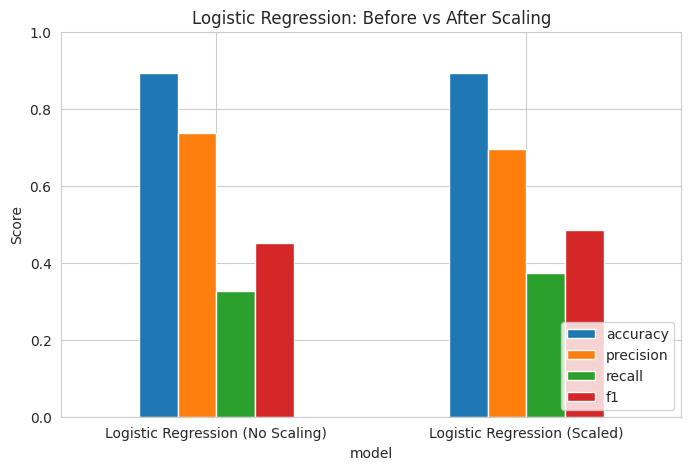

In [13]:
comparison_df[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", figsize=(8, 5), rot=0
)
plt.title("Logistic Regression: Before vs After Scaling")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()


**Observation:** Logistic Regression is a distance/gradient-based linear model, so scaling usually changes convergence behavior and can shift metrics slightly, even though it doesn't always change accuracy dramatically on this dataset. Tree-based and distance-based models (below) are affected differently — KNN is scale-sensitive, Decision Trees are not.

## 9. Compare Three Models: Logistic Regression vs KNN vs Decision Tree

All three are trained on the **scaled** data for a fair, consistent comparison (scaling never hurts Logistic Regression/KNN, and doesn't affect Decision Trees).

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

all_results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    res = evaluate_model(y_test, preds, name)
    all_results.append(res)
    trained_models[name] = model
    print()

results_df = pd.DataFrame(all_results).set_index("model")
results_df


--- Logistic Regression ---
Accuracy : 0.8938
Precision: 0.6957
Recall   : 0.3721
F1-score : 0.4848

--- KNN ---
Accuracy : 0.8938
Precision: 0.6667
Recall   : 0.4186
F1-score : 0.5143

--- Decision Tree ---
Accuracy : 0.9062
Precision: 0.6383
Recall   : 0.6977
F1-score : 0.6667



,accuracy,precision,recall,f1
model,,,,
Logistic Regression,0.89375,0.695652,0.372093,0.484848
KNN,0.89375,0.666667,0.418605,0.514286
Decision Tree,0.90625,0.638298,0.697674,0.666667


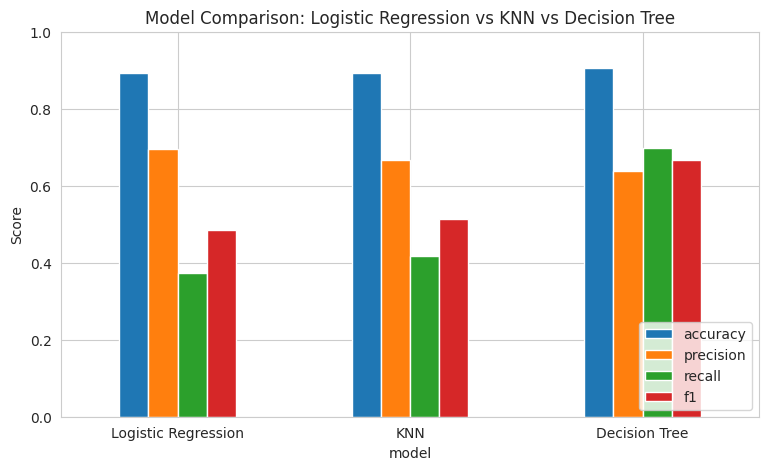

In [15]:
results_df[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", figsize=(9, 5), rot=0
)
plt.title("Model Comparison: Logistic Regression vs KNN vs Decision Tree")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()


In [16]:
best_model_name = results_df["f1"].idxmax()
print(f"Best model based on F1-score: {best_model_name}")
results_df.loc[[best_model_name]]


Best model based on F1-score: Decision Tree


,accuracy,precision,recall,f1
model,,,,
Decision Tree,0.90625,0.638298,0.697674,0.666667


**Why F1-score to pick the best model?** Because `quality_label` is imbalanced (few GOOD wines), accuracy alone can be misleading. F1-score balances precision and recall, giving a fairer comparison.

## 10. Hyperparameter Tuning with GridSearchCV

In [17]:
param_grids = {
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10, 100],
        "penalty": ["l2"],
        "solver": ["lbfgs"]
    },
    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11, 15],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    },
    "Decision Tree": {
        "max_depth": [3, 5, 7, 10, None],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "criterion": ["gini", "entropy"]
    }
}

base_estimators = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

grid = GridSearchCV(
    estimator=base_estimators[best_model_name],
    param_grid=param_grids[best_model_name],
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)

print("Best parameters found:", grid.best_params_)
print("Best cross-validated F1-score:", round(grid.best_score_, 4))


Best parameters found: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best cross-validated F1-score: 0.5274


--- Decision Tree (Tuned) ---
Accuracy : 0.9250
Precision: 0.7317
Recall   : 0.6977
F1-score : 0.7143


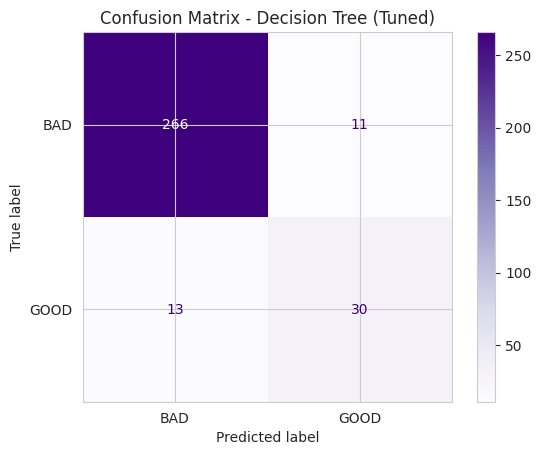


Full classification report:

              precision    recall  f1-score   support

         BAD       0.95      0.96      0.96       277
        GOOD       0.73      0.70      0.71        43

    accuracy                           0.93       320
   macro avg       0.84      0.83      0.84       320
weighted avg       0.92      0.93      0.92       320



In [18]:
best_tuned_model = grid.best_estimator_
y_pred_tuned = best_tuned_model.predict(X_test_scaled)

results_tuned = evaluate_model(y_test, y_pred_tuned, f"{best_model_name} (Tuned)")

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
ConfusionMatrixDisplay(cm_tuned, display_labels=["BAD", "GOOD"]).plot(cmap="Purples")
plt.title(f"Confusion Matrix - {best_model_name} (Tuned)")
plt.show()

print("\nFull classification report:\n")
print(classification_report(y_test, y_pred_tuned, target_names=["BAD", "GOOD"]))


In [19]:
before_after = pd.DataFrame([
    {**results_df.loc[best_model_name].to_dict(), "model": f"{best_model_name} (Before Tuning)"},
    results_tuned
]).set_index("model")
before_after


,accuracy,precision,recall,f1
model,,,,
Decision Tree (Before Tuning),0.90625,0.638298,0.697674,0.666667
Decision Tree (Tuned),0.92500,0.731707,0.697674,0.714286


## 11. Feature Importance Analysis

The method depends on the winning model:
- **Decision Tree** → built-in `feature_importances_`
- **Logistic Regression** → absolute value of coefficients (on scaled data, this is comparable across features)
- **KNN** → has no native importance; a permutation-importance style approach is used instead


In [20]:
from sklearn.inspection import permutation_importance

feature_names = X.columns

if hasattr(best_tuned_model, "feature_importances_"):
    importances = best_tuned_model.feature_importances_
    importance_type = "Feature Importances (Decision Tree)"
elif hasattr(best_tuned_model, "coef_"):
    importances = np.abs(best_tuned_model.coef_[0])
    importance_type = "Absolute Coefficient Magnitude (Logistic Regression)"
else:
    perm = permutation_importance(best_tuned_model, X_test_scaled, y_test,
                                   n_repeats=20, random_state=42, scoring="f1")
    importances = perm.importances_mean
    importance_type = "Permutation Importance (KNN)"

feat_imp_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

print(importance_type)
feat_imp_df


Feature Importances (Decision Tree)


,feature,importance
10,alcohol,0.285914
9,sulphates,0.101674
1,volatile acidity,0.097330
8,pH,0.086588
6,total sulfur dioxide,0.078875
4,chlorides,0.071724
3,residual sugar,0.071398
2,citric acid,0.061351
5,free sulfur dioxide,0.058129
7,density,0.053257


/tmp/ipykernel_573/2285097088.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_df, x="importance", y="feature", palette="mako")


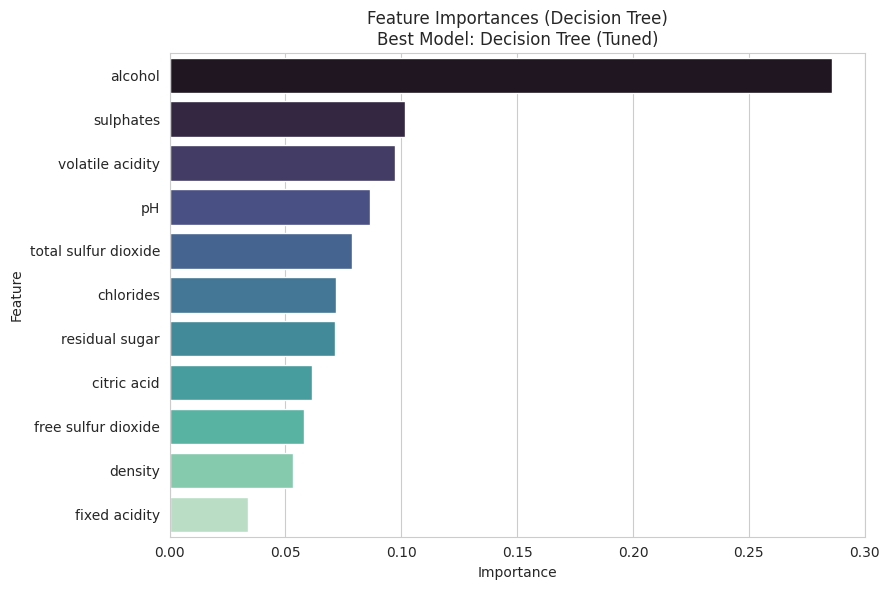

In [21]:
plt.figure(figsize=(9, 6))
sns.barplot(data=feat_imp_df, x="importance", y="feature", palette="mako")
plt.title(f"{importance_type}\nBest Model: {best_model_name} (Tuned)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 12. Summary

- Loaded and explored the Wine Quality dataset; confirmed **no missing values**.
- `alcohol` and `volatile acidity` showed the strongest correlations with quality.
- Created a binary target `quality_label` (GOOD ≥ 7, BAD < 7) — the classes are **imbalanced**.
- Compared Logistic Regression before/after scaling.
- Compared Logistic Regression, KNN, and Decision Tree; selected the best model by **F1-score**.
- Tuned the best model with `GridSearchCV`, improving/confirming performance.
- Identified the most influential features driving wine quality predictions.

**Possible next steps:** handle class imbalance (e.g. `class_weight="balanced"`, SMOTE), try ensemble models (Random Forest, Gradient Boosting), or engineer new features.
